In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
#Import Data
Data = pd.read_csv('/content/salary_data.csv')
Data.head()

#Assign Values
x = Data[['YearsExperience']]
y = Data['Salary']

In [11]:
#Train test
x_train , x_test, y_train, y_test = train_test_split(x, y, test_size=0.2 , random_state=42)

#Model Train
model = LinearRegression()
model.fit(x_train, y_train)


LinearRegression()

In [12]:
#Predict
predicted_out = model.predict(x_test)
print(predicted_out)

print(y_test.values)

[115790.21011287  71498.27809463 102596.86866063  75267.80422384
  55477.79204548  60189.69970699]
[112635.  67938. 113812.  83088.  64445.  57189.]


In [13]:
#Comparison
comparison = pd.DataFrame({
    'Actual Salary' : y_test.values,
    'Predicted Salary' : predicted_out
})

comparison['Error'] = (comparison['Actual Salary'] - comparison['Predicted Salary'])

print(comparison.round(2))

   Actual Salary  Predicted Salary     Error
0       112635.0         115790.21  -3155.21
1        67938.0          71498.28  -3560.28
2       113812.0         102596.87  11215.13
3        83088.0          75267.80   7820.20
4        64445.0          55477.79   8967.21
5        57189.0          60189.70  -3000.70


In [14]:

#Model Evaluation
Mae = mean_absolute_error(y_test, predicted_out)
Mse = mean_squared_error(y_test, predicted_out)
r2 = r2_score(y_test, predicted_out)

print('Mean Absolute Error : ' , Mae)
print('Mean Squared Error : ', Mse)
print('R2 Score : ', r2)

Mean Absolute Error :  6286.453830757749
Mean Squared Error :  49830096.85590839
R2 Score :  0.9024461774180497


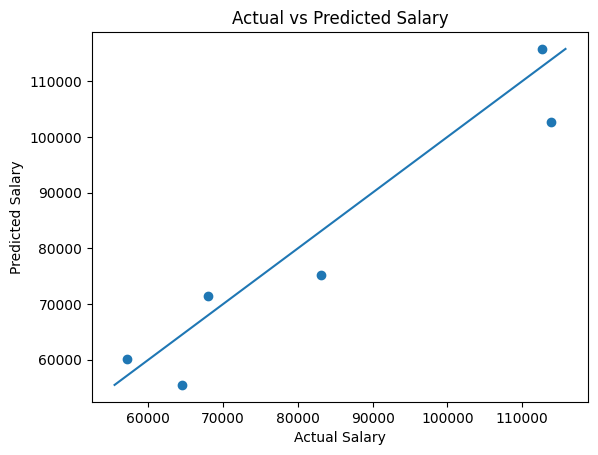

In [25]:

plt.scatter(y_test, predicted_out)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

# Perfect predictions would lie on this line
minimum = min(y_test.min(), predicted_out.min())
maximum = max(y_test.max(), predicted_out.max())
plt.plot([minimum, maximum], [minimum, maximum])

plt.show()


In [17]:


experience = float(input("Enter years of experience: "))

new_employee = pd.DataFrame({
    'YearsExperience': [experience]
})

predicted_salary = model.predict(new_employee)[0]

print(f"Predicted Salary: ₹{predicted_salary:,.2f}")



Enter years of experience: 6
Predicted Salary: ₹81,864.47
